Found 70295 images belonging to 38 classes.
Found 17572 images belonging to 38 classes.
🔵 Phase 1: Training top layers only...
Epoch 1/15
1099/1099 - 680s - loss: 0.8090 - accuracy: 0.7618 - val_loss: 0.2735 - val_accuracy: 0.9103 - 680s/epoch - 619ms/step
Epoch 2/15
1099/1099 - 677s - loss: 0.3369 - accuracy: 0.8945 - val_loss: 0.2123 - val_accuracy: 0.9313 - 677s/epoch - 616ms/step
Epoch 3/15
1099/1099 - 676s - loss: 0.2643 - accuracy: 0.9185 - val_loss: 0.2006 - val_accuracy: 0.9349 - 676s/epoch - 616ms/step
Epoch 4/15
1099/1099 - 682s - loss: 0.2310 - accuracy: 0.9294 - val_loss: 0.1986 - val_accuracy: 0.9331 - 682s/epoch - 620ms/step
Epoch 5/15
1099/1099 - 685s - loss: 0.2037 - accuracy: 0.9375 - val_loss: 0.1657 - val_accuracy: 0.9476 - 685s/epoch - 624ms/step
Epoch 6/15
1099/1099 - 691s - loss: 0.1871 - accuracy: 0.9426 - val_loss: 0.1810 - val_accuracy: 0.9416 - 691s/epoch - 629ms/step
Epoch 7/15
1099/1099 - 675s - loss: 0.1767 - accuracy: 0.9456 - val_loss: 0.1888 - val_accura

C:\ProgramData\anaconda3\envs\tf_cuda_env\lib\site-packages\keras\engine\functional.py:1410: CustomMaskWarning: Custom mask layers require a config and must override get_config. When loading, the custom mask layer must be passed to the custom_objects argument.
  layer_config = serialize_layer_fn(layer)


✅ Model saved: MobileNetV2_ATT_ATTRUS_TUNED_full_model.h5

📊 Classification Report for MobileNetV2_ATT_ATTRUS_TUNED:
                                            precision    recall  f1-score   support

                          Apple_BlackRot_0       0.99      1.00      0.99       497
                         Apple_CedarRust_1       1.00      1.00      1.00       440
                           Apple_Healthy_2       0.98      1.00      0.99       502
                              Apple_Scab_3       1.00      0.99      0.99       504
                       Blueberry_Healthy_4       1.00      0.98      0.99       454
                          Cherry_Healthy_5       0.99      1.00      0.99       456
                    Cherry_PowderyMildew_6       1.00      1.00      1.00       421
     Corn_Maize_Cercospora_Grey_LeafSpot_7       0.97      0.92      0.95       410
                   Corn_Maize_CommonRust_8       0.99      1.00      1.00       477
                      Corn_Maize_Healthy_9

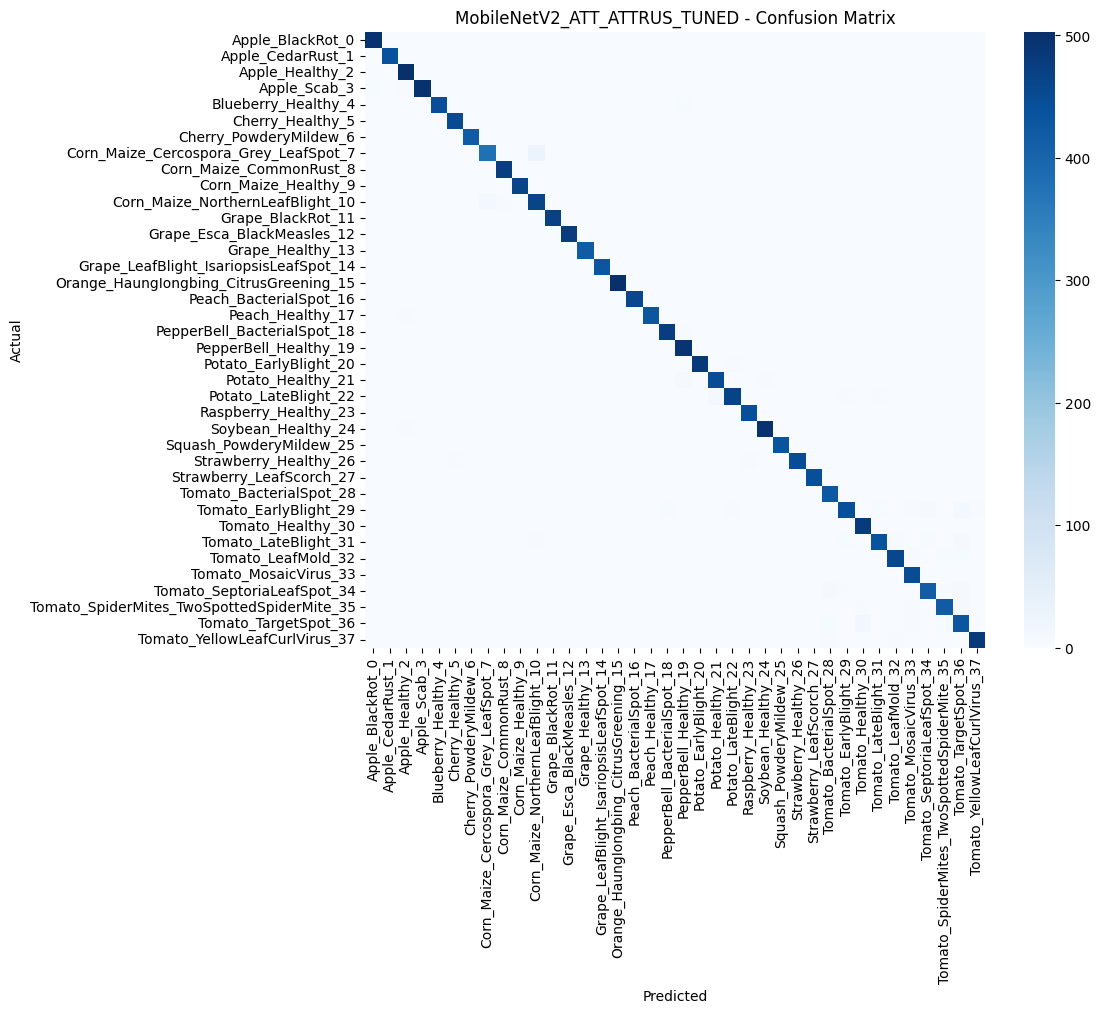

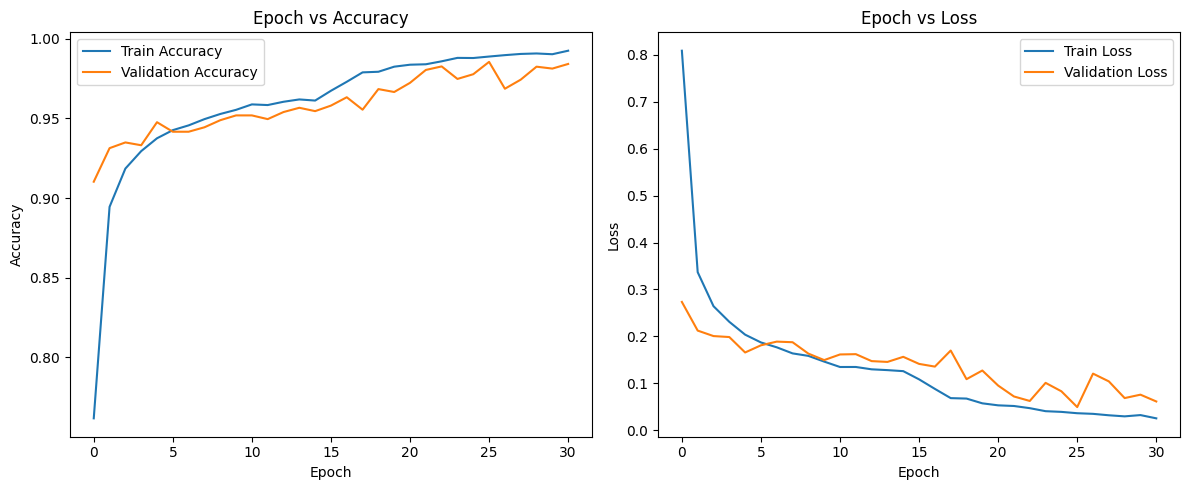

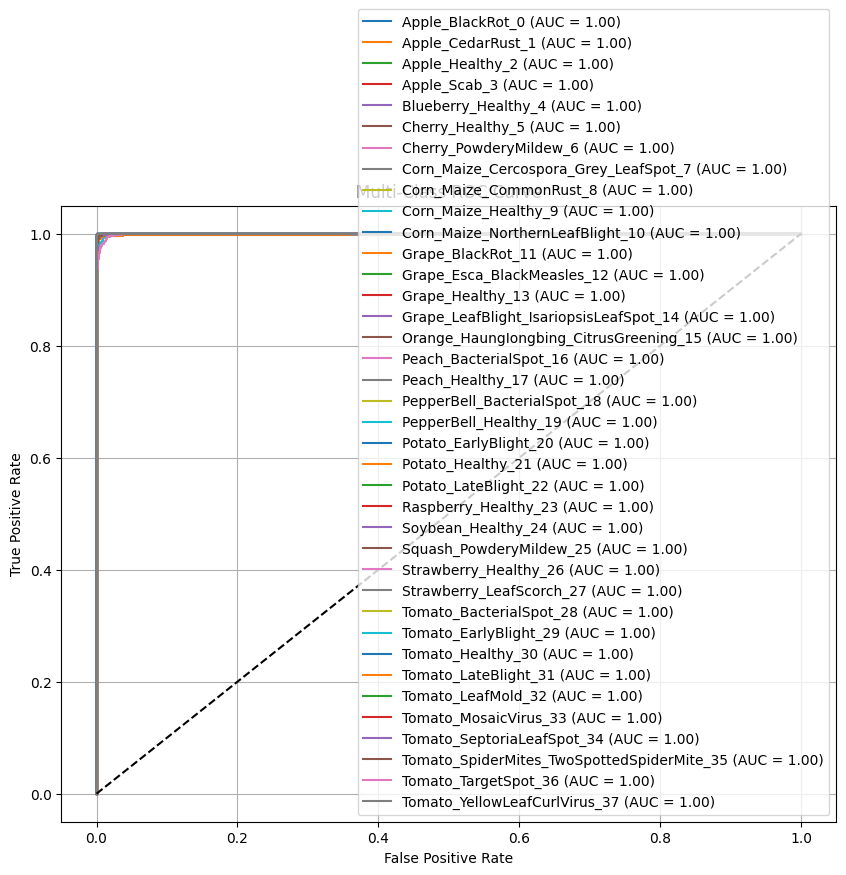

In [9]:
import os
import pickle
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import load_model
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc
from sklearn.preprocessing import label_binarize

# ========== Custom Layers ==========
class AttentionBlock(tf.keras.layers.Layer):
    def __init__(self, channels, **kwargs):
        super(AttentionBlock, self).__init__(**kwargs)
        self.channels = channels
        self.global_pool = layers.GlobalAveragePooling2D()
        self.dense1 = layers.Dense(channels // 8, activation='relu')
        self.dense2 = layers.Dense(channels, activation='sigmoid')
        self.reshape = layers.Reshape((1, 1, channels))
        self.multiply = layers.Multiply()

    def call(self, inputs):
        x = self.global_pool(inputs)
        x = self.dense1(x)
        x = self.dense2(x)
        x = self.reshape(x)
        return self.multiply([inputs, x])

    def get_config(self):
        config = super().get_config()
        config.update({"channels": self.channels})
        return config

class ATTRUSBlock(tf.keras.layers.Layer):
    def __init__(self, channels, **kwargs):
        super(ATTRUSBlock, self).__init__(**kwargs)
        self.channels = channels
        self.global_pool = layers.GlobalAveragePooling2D()
        self.dense1 = layers.Dense(channels // 8, activation='relu')
        self.dense2 = layers.Dense(channels, activation='sigmoid')
        self.reshape = layers.Reshape((1, 1, channels))
        self.multiply = layers.Multiply()
        self.add = layers.Add()

    def call(self, inputs):
        x = self.global_pool(inputs)
        x = self.dense1(x)
        x = self.dense2(x)
        x = self.reshape(x)
        scaled = self.multiply([inputs, x])
        return self.add([inputs, scaled])

    def get_config(self):
        config = super().get_config()
        config.update({"channels": self.channels})
        return config

# ========== Paths and Params ==========
train_dir = 'plntdata/Final_DataSet/train'
val_dir = 'plntdata/Final_DataSet/valid'

IMG_SIZE = (224, 224)
BATCH_SIZE = 64
EPOCHS_PHASE1 = 15
EPOCHS_PHASE2 = 25

# ========== Data Generators ==========
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=True)

val_gen = val_datagen.flow_from_directory(
    val_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False)

# ========== Build Model ==========
def build_model(num_classes, train_base=True, lr=1e-3):
    base_model = MobileNetV2(include_top=False, input_shape=(224, 224, 3), weights='imagenet')
    base_model.trainable = train_base

    inputs = layers.Input(shape=(224, 224, 3))
    x = base_model(inputs, training=train_base)
    x = AttentionBlock(x.shape[-1])(x)
    x = ATTRUSBlock(x.shape[-1])(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='categorical_crossentropy', metrics=['accuracy'])
    return model

# ========== Plotting ==========
def plot_accuracy_loss(history_dict, model_name):
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history_dict['accuracy'], label='Train Accuracy')
    plt.plot(history_dict['val_accuracy'], label='Validation Accuracy')
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Epoch vs Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history_dict['loss'], label='Train Loss')
    plt.plot(history_dict['val_loss'], label='Validation Loss')
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Epoch vs Loss")
    plt.legend()

    plt.tight_layout()
    plt.savefig(f"{model_name}_Accuracy_Loss.png")
    plt.show()

def plot_multiclass_roc(y_true, y_probs, class_names, model_name):
    y_true_bin = label_binarize(y_true, classes=range(len(class_names)))
    fpr, tpr, roc_auc = {}, {}, {}

    for i in range(len(class_names)):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(10, 8))
    for i in range(len(class_names)):
        plt.plot(fpr[i], tpr[i], label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})')

    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Multi-Class ROC Curve')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.savefig(f"{model_name}_ROC_Curve.png")
    plt.show()

# ========== Training Pipeline ==========
def train_pipeline(model_name="MobileNetV2_ATT_ATTRUS_TUNED"):
    print("🔵 Phase 1: Training top layers only...")
    model = build_model(num_classes=train_gen.num_classes, train_base=False, lr=1e-3)
    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

    history1 = model.fit(train_gen, validation_data=val_gen, epochs=EPOCHS_PHASE1, callbacks=[early_stop], verbose=2)

    print("🟢 Phase 2: Fine-tuning entire model...")
    model.trainable = True
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss='categorical_crossentropy', metrics=['accuracy'])

    history2 = model.fit(train_gen, validation_data=val_gen, epochs=EPOCHS_PHASE2, callbacks=[early_stop], verbose=2)

    # Combine histories
    full_history = {}
    for key in history1.history:
        full_history[key] = history1.history[key] + history2.history[key]

    # Save history
    with open(f'{model_name}_history.pkl', 'wb') as f:
        pickle.dump(full_history, f)
    print(f"✅ Training history saved as {model_name}_history.pkl")

    # Save model
    model.save(f"{model_name}_full_model.h5")
    print(f"✅ Model saved: {model_name}_full_model.h5")

    # Reload model
    model = load_model(f"{model_name}_full_model.h5", custom_objects={
        'AttentionBlock': AttentionBlock,
        'ATTRUSBlock': ATTRUSBlock
    })

    # Evaluation
    val_gen.reset()
    preds = model.predict(val_gen)
    y_pred = np.argmax(preds, axis=1)
    y_true = val_gen.classes
    class_names = list(val_gen.class_indices.keys())

    print(f"\n📊 Classification Report for {model_name}:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)

    print(f"\n✅ Accuracy:  {acc:.4f}")
    print(f"✅ Precision: {prec:.4f}")
    print(f"✅ Recall:    {rec:.4f}")
    print(f"✅ F1 Score:  {f1:.4f}")

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=False, fmt="d", xticklabels=class_names, yticklabels=class_names, cmap="Blues")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.savefig(f"{model_name}_confusion_matrix.png")
    plt.show()

    # Plot metrics and ROC
    plot_accuracy_loss(full_history, model_name)
    plot_multiclass_roc(y_true, preds, class_names, model_name)

# ========== Run Pipeline ==========
train_pipeline()
